# SOFR curve PCA and butterfly mean reversion - walkthrough

**Question.** Which SOFR spreads and butterflies are rich or cheap relative to the curve's normal shape, and does
trading them back to fair value make money **after costs, out of sample**?

**Answer in one line.** Curvature (flies and double flies) does mean-revert, measurably and out of sample, but by
only ~0.2-1.2 bp over ten days - far less than the 4.8-9.6 bp it costs to cross every leg. As a stand-alone
taker strategy it loses money; as a screen for *timing* trades you already want to do, it is useful.

This notebook walks through every step with the real numbers. All of it runs from `src/sofr_pca`; the same code
produces the README charts via `scripts/run_all.py`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

from sofr_pca import plots, backtest as bt
from sofr_pca.config import load_config
from sofr_pca.analysis import run_analysis
from sofr_pca.data import roll_days
from sofr_pca.structures import structure_values
from sofr_pca.screen import top_rich_cheap
plots.apply_style()
cfg = load_config()
r = run_analysis(cfg)          # ~20 seconds: data -> PCA -> residuals -> backtests -> screen
curve = r["curve"]
print(f"{len(curve.dates)} sessions, {curve.dates[0].date()} to {curve.dates[-1].date()}, "
      f"{curve.levels.shape[1]} constant positions, {r['rolls']} quarterly rolls")

2112 sessions, 2018-06-01 to 2026-10-19, 12 constant positions, 33 quarterly rolls


## Step 1 - A roll-safe curve

* Rate = 100 - price, in basis points. Position 1 = the first quarterly contract (H/M/U/Z) still trading; positions
  1-12 cover the next three years.
* On a roll day every position moves to a later contract. If we differenced the generic position series we would book
  the gap between two *different* contracts as a move. So daily changes are computed on each **fixed** contract and only
  then placed on the position the contract occupies today.

Below: on each roll day, the change we use for position 1 versus the fake "generic" jump.

In [2]:
rolls = curve.dates[roll_days(curve).to_numpy()]
rows = []
for d in rolls[-6:]:
    i = curve.dates.get_loc(d); prev = curve.dates[i - 1]
    rows.append(dict(roll_day=d.date(), old_front=curve.contracts.iat[i - 1, 0], new_front=curve.contracts.iat[i, 0],
                     fixed_contract_change_bp=round(curve.changes.iat[i, 0], 2),
                     generic_jump_bp=round(curve.levels.iat[i, 0] - curve.levels.iat[i - 1, 0], 2)))
pd.DataFrame(rows)

,roll_day,old_front,new_front,fixed_contract_change_bp,generic_jump_bp
0,2025-06-18,SR3H25,SR3M25,0.50,-0.75
1,2025-09-17,SR3M25,SR3U25,-0.25,-34.00
2,2025-12-17,SR3U25,SR3Z25,-0.25,-38.00
3,2026-03-18,SR3Z25,SR3H26,0.25,0.25
4,2026-06-17,SR3H26,SR3M26,3.25,6.25
5,2026-09-16,SR3M26,SR3U26,1.50,34.75


The generic jump is often several bp (the front contract is replaced by one three months later); the real move
of the new front contract is usually a fraction of that. Every number downstream uses the real move.

## Step 2 - PCA of daily changes

PCA finds the few "shapes" that explain most of the curve's daily moves. We use **changes** (not levels) because
levels trend for years and are not stationary.

,share,cumulative
PC1,0.905,0.905
PC2,0.073,0.978
PC3,0.015,0.993
PC4,0.004,0.997
PC5,0.001,0.998


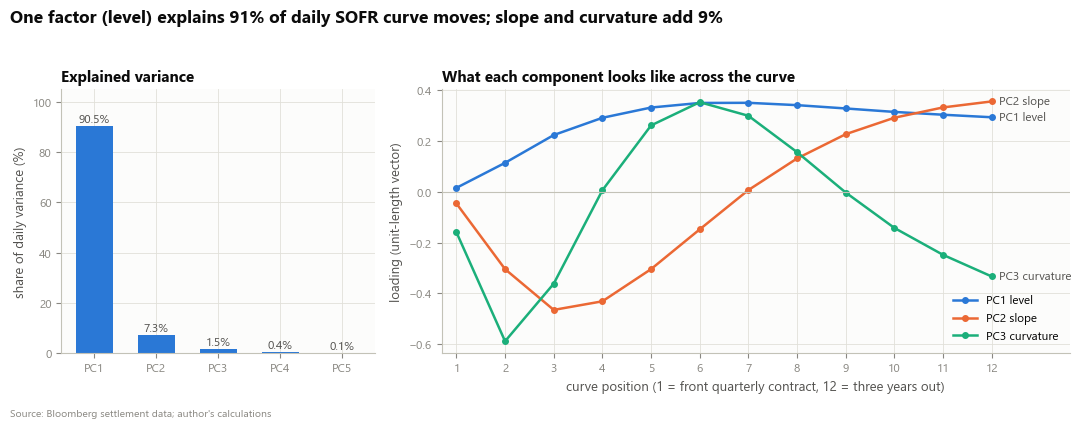

In [3]:
pc = r["pca"]
display(pc["explained"].round(3))
plots.fig_pca(pc["full"]);

* **PC1 (level)**: the whole Fed path re-prices together. It explains ~90% of daily variance. Note the loading is
  small at position 1: the front contract is already partly fixed by realised SOFR.
* **PC2 (slope)**: the front 1-2 years move against the back - steepening / flattening.
* **PC3 (curvature)**: the belly (positions 4-8) moves against both wings. Flies are bets on this - and on what is left
  after it.

### Are the shapes stable?

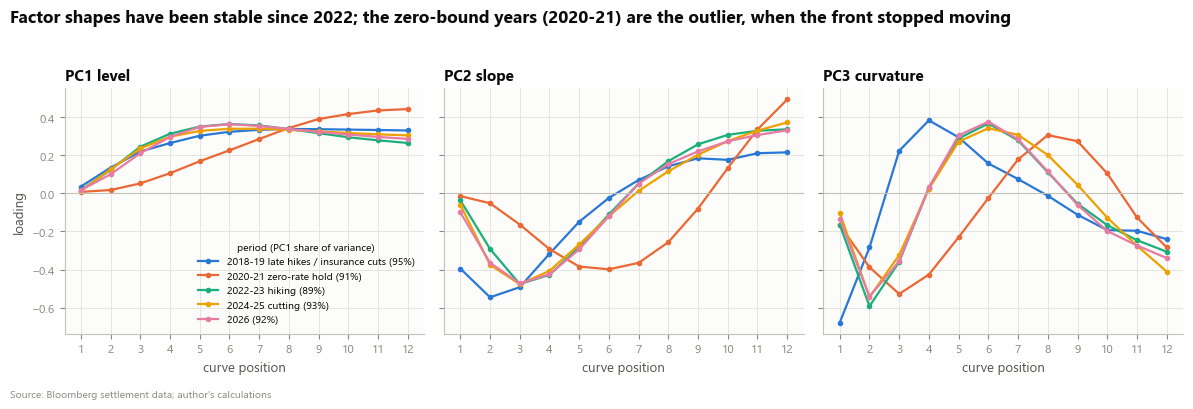

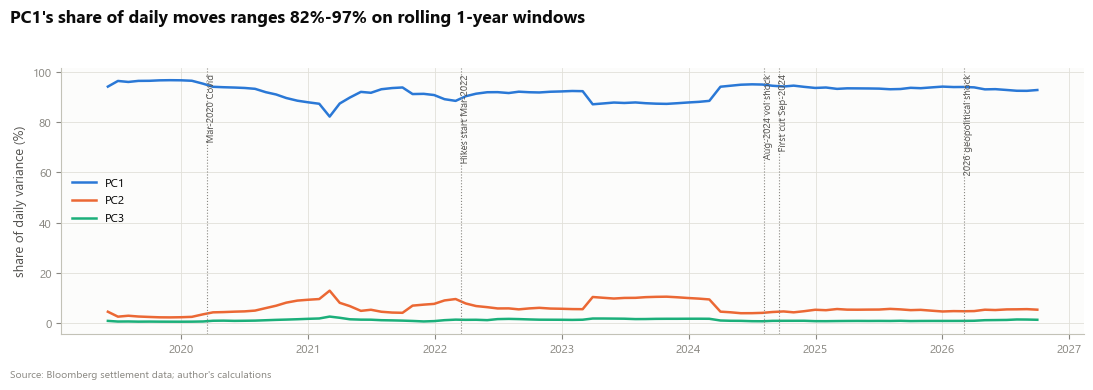

In [4]:
plots.fig_regime_loadings(pc["by_regime"]);
plots.fig_rolling_explained(pc["rolling"], cfg["events"]);

Since 2022 the three shapes are almost identical across hiking, cutting and 2026. The outlier is the zero-rate hold
(2020-21): with the Fed pinned at zero, the front stopped moving and the level factor lived in the back. A model fitted
in 2021 would therefore misread 2022 - one reason to re-estimate on a rolling window.

## Step 3 - Rich / cheap residuals

Each structure's level is regressed on the PC1-PC3 scores over the fitting window:
`y(t) = a + b1 PC1(t) + b2 PC2(t) + b3 PC3(t) + e(t)`. The residual `e` is what the curve's normal shapes cannot
explain; its z-score against its own trailing 63-day mean and standard deviation is the signal.

In [5]:
blk = r["blocks_all"][-1]
print("latest walk-forward model, fitted on data up to", blk.model.fit_end.date())
blk.model.params.loc[["FLY 3-4-5", "FLY 5-6-7", "FLY 8-9-10", "DFLY 4-5-6-7", "SPR 4-5"]].round(3)

latest walk-forward model, fitted on data up to 2026-10-01


,a,b_PC1,b_PC2,b_PC3,sigma,phi,half_life
FLY 3-4-5,1.319,-0.043,0.111,-0.117,1.251,0.859,4.556
FLY 5-6-7,0.177,-0.014,-0.012,-0.175,0.805,0.787,2.888
FLY 8-9-10,1.458,-0.002,-0.020,0.058,0.506,0.688,1.851
DFLY 4-5-6-7,0.347,-0.018,0.036,-0.061,1.192,0.707,2.003
SPR 4-5,3.504,-0.042,-0.143,-0.254,1.034,0.913,7.616


### PCA-neutral weights vs the textbook 1:-2:1

The PCA-neutral fly keeps the middle at -2 and re-sizes the wings so the fly has zero exposure to PC1 and PC2.
It does what it promises - the betas go to zero - but its *level* is **less** mean-reverting than 1:-2:1, not more.
The textbook fly's apparent mean reversion partly comes from a small, mean-reverting level/slope exposure.

In [6]:
r["pca_vs_trad"].query("structure in ['FLY 2-3-4','FLY 4-5-6','FLY 5-6-7','FLY 8-9-10']")

,structure,weighting,weights,beta_pc1,beta_pc2,level_half_life,level_adf_p,daily_vol_bp
2,FLY 2-3-4,1:-2:1,1.00 : -2.00 : 1.00,-0.037,0.111,37.3,0.007,1.90
3,FLY 2-3-4,PCA-neutral,1.97 : -2.00 : 0.76,0.000,-0.008,1080.9,0.824,2.22
6,FLY 4-5-6,1:-2:1,1.00 : -2.00 : 1.00,-0.021,0.014,43.2,0.005,0.90
7,FLY 4-5-6,PCA-neutral,1.07 : -2.00 : 1.01,0.000,-0.001,238.0,0.453,0.75
8,FLY 5-6-7,1:-2:1,1.00 : -2.00 : 1.00,-0.017,-0.005,39.5,0.000,0.76
9,FLY 5-6-7,PCA-neutral,1.00 : -2.00 : 1.05,-0.000,-0.001,177.8,0.442,0.65
14,FLY 8-9-10,1:-2:1,1.00 : -2.00 : 1.00,-0.001,-0.019,34.4,0.006,0.52
15,FLY 8-9-10,PCA-neutral,0.84 : -2.00 : 1.18,0.000,-0.000,39.7,0.014,0.51


## Step 4 - How fast do residuals revert?

AR(1): `e(t) = c + phi e(t-1) + noise`; half-life = `-ln 2 / ln phi`. ADF tests whether the residual has a unit root.

,resid_sigma_bp,half_life_full,adf_p_full,half_life_wf_median
structure,,,,
FLY 1-2-3,16.78,19.0,0.0,7.0
FLY 2-3-4,5.95,12.2,0.0,5.5
FLY 3-4-5,3.95,17.7,0.0,4.8
FLY 4-5-6,2.75,15.1,0.0,6.2
FLY 5-6-7,2.06,11.8,0.0,4.1
FLY 6-7-8,2.03,13.6,0.0,6.6
FLY 7-8-9,1.67,12.7,0.0,4.9
FLY 8-9-10,1.69,13.0,0.0,3.5
FLY 9-10-11,1.29,8.0,0.0,3.4


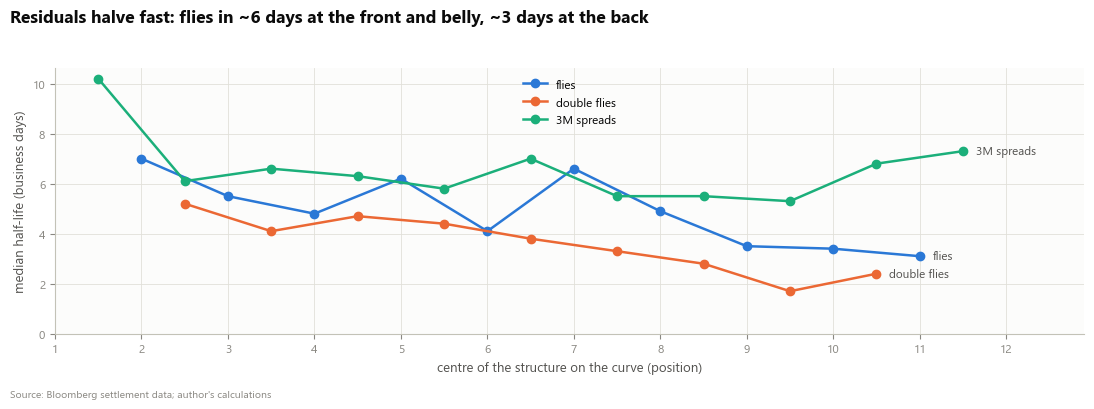

In [7]:
st = r["stats"]
display(st[st.family.isin(["fly", "dfly"])][["resid_sigma_bp", "half_life_full", "adf_p_full", "half_life_wf_median"]])
plots.fig_half_life(st);

Every residual is stationary by ADF on the full sample, and half-lives are short: 3-7 days for flies in the
walk-forward windows. Short half-life is good news for a mean-reversion trade - and bad news for costs, because the
move you can capture before it disappears is small.

## Step 5 - Is the signal real? (before any trading rules)

For every out-of-sample day and structure: if |z| sat in a bucket, how far did the structure move back toward fair
value over the next 5 / 10 / 20 days?

family,dfly,fly,spread1y,spread3m
z_bucket,,,,
1.5-2.0,0.61,0.30,-0.12,0.05
2.0-2.5,0.19,0.24,-0.18,-0.09
2.5-3.5,0.62,0.27,-0.70,-0.00
3.5-9.0,1.16,0.87,-0.12,0.31


family,dfly,fly,spread1y,spread3m
z_bucket,,,,
1.5-2.0,0.60,0.54,0.49,0.48
2.0-2.5,0.57,0.56,0.50,0.46
2.5-3.5,0.58,0.53,0.48,0.50
3.5-9.0,0.59,0.53,0.50,0.47


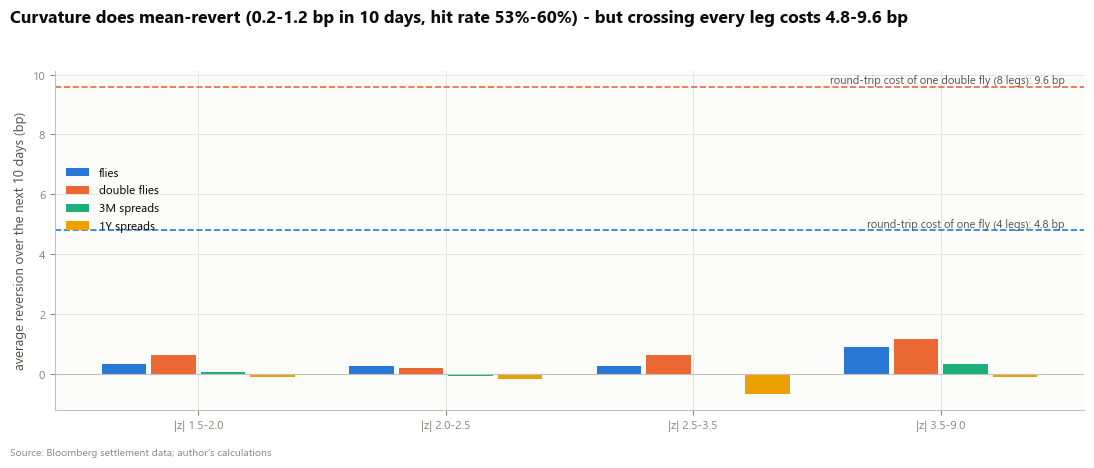

In [8]:
sig = r["signal"]
display(sig[sig.horizon_days == 10].pivot(index="z_bucket", columns="family", values="avg_reversion_bp").round(2))
display(sig[sig.horizon_days == 10].pivot(index="z_bucket", columns="family", values="hit_rate").round(2))
plots.fig_signal_vs_cost(sig, 10);

Flies and double flies revert 0.2-1.2 bp in ten days with 53-60% hit rates - a real, positive edge that grows
with |z|. Spreads do not revert at all (hit rates below 50%): 3M and 1Y spreads are dominated by the Fed path, which
trends. But the edge is an order of magnitude smaller than the cost of trading a fly leg by leg.

## Step 6 - Walk-forward backtest, net of costs

* Fit on the previous 252 days, trade the next 63 with frozen parameters, refit, repeat. Out-of-sample from Jul-2020.
* Enter when 2 < |z| < 3.5 (signal at close t, trade at the settle of t+1). Exit at |z| < 0.5, stop at |z| > 3.5,
  time stop 2 x half-life. At most two open trades per curve region; no two trades share a contract.
* Costs: 1 tick (0.5 bp) per leg per side + $2.50 per contract per side.

,trades,hit_rate_gross,avg_gross_bp,gross_bp,net_usd,sharpe_gross,sharpe_net,max_dd_usd
out-of-sample (walk-forward),361,0.462604,0.254848,92.0,-55060.0,0.485955,-6.265456,-55060.0
"in-sample (one fit, all data)",245,0.481633,0.70102,171.75,-36986.25,0.889404,-5.158697,-36986.25


,trades,hit_rate_gross,avg_gross_bp,net_usd,sharpe_gross,sharpe_net
spread3m,377,0.448276,-0.223475,-24726.25,-0.330934,-3.5661
spread1y,259,0.494208,0.450772,-12621.25,0.221983,-0.941769
fly,318,0.443396,0.187893,-36666.25,0.354723,-5.968618
dfly,267,0.483146,0.382959,-61523.75,0.680707,-6.909611


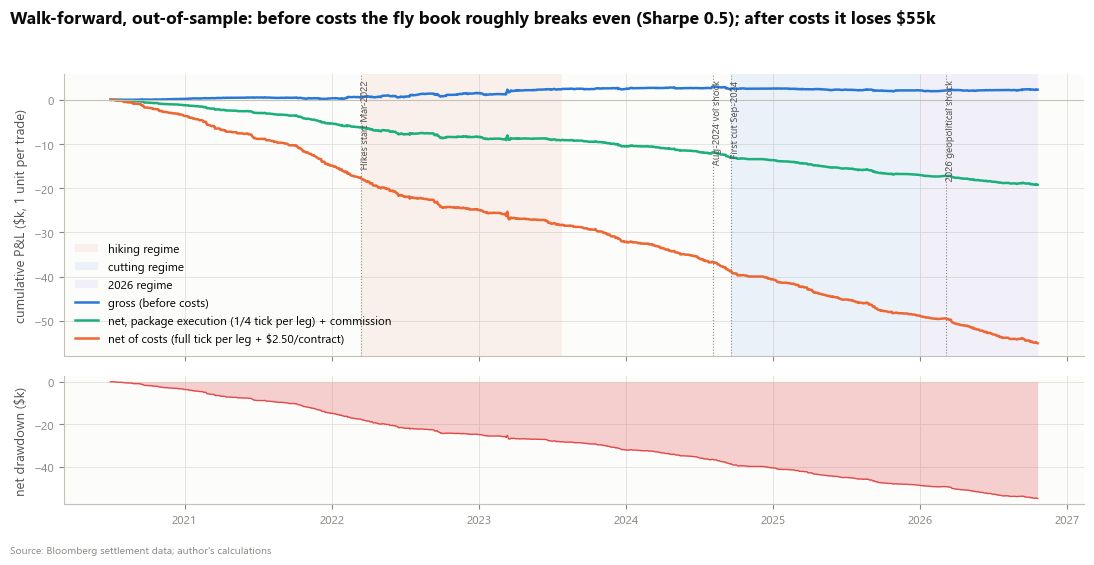

In [9]:
b = r["bt"]
display(b["headline"][["trades", "hit_rate_gross", "avg_gross_bp", "gross_bp", "net_usd", "sharpe_gross", "sharpe_net", "max_dd_usd"]].round(2))
display(b["by_family"][["trades", "hit_rate_gross", "avg_gross_bp", "net_usd", "sharpe_gross", "sharpe_net"]].round(2))
plots.fig_equity(b["main"], cfg["regimes"], cfg["events"], alt=bt.net_with_cost(b["main"], 0.125),
                 alt_label="net, package execution (1/4 tick per leg) + commission");

,scenario,tick_bp_per_leg,net_usd,sharpe_net,max_dd_usd
0,commission only,0.00,-7260.0,-1.45,-7310.0
1,package execution (1/4 tick per leg),0.12,-19210.0,-3.40,-19210.0
2,half tick per leg,0.25,-31160.0,-4.75,-31160.0
3,full tick per leg (default),0.50,-55060.0,-6.27,-55060.0
4,gross (no costs at all),NaN,2300.0,0.49,-1075.0


,variant,trades,hit_rate,avg_hold_days,gross_bp,net_bp,net_usd,sharpe_gross,sharpe_net
0,"spec rule (exit 0.5, stop 3.5, 2x half-life)",361,0.04,7.12,92.00,-2202.40,-55060.00,0.49,-6.27
1,exit at z = 0,340,0.04,8.02,74.75,-2090.05,-52251.25,0.41,-6.13
2,no stop-loss,343,0.05,7.48,152.75,-1992.85,-49821.25,0.75,-5.87
3,fixed 10-day hold,258,0.02,10.96,22.25,-1542.55,-38563.75,0.11,-5.21


,net_usd,sharpe_net,days
2026,-6232.50,-7.12,201.0
cutting,-10161.25,-7.47,324.0
hiking,-10601.25,-3.97,343.0
hold,-28065.00,-7.73,719.0


break-even cost per contract per side: 0.036 bp ($0.90)


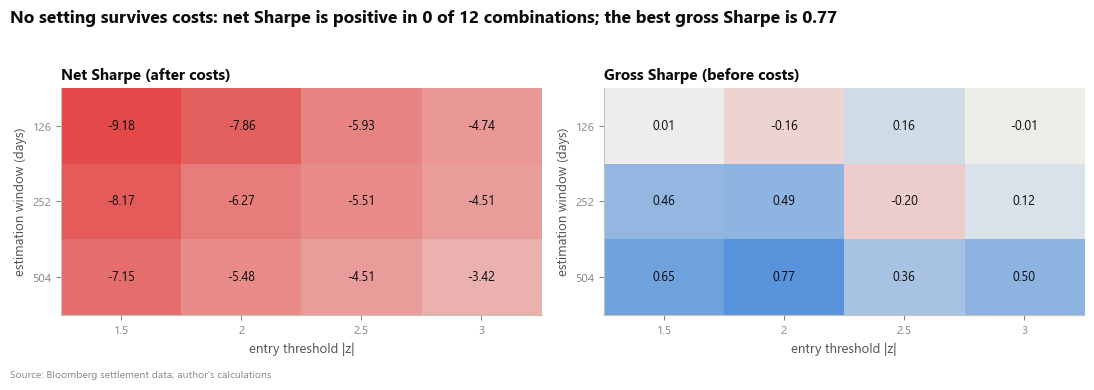

In [10]:
display(b["costs"].round(2)); display(b["variants"].round(2)); display(b["regime"].round(2))
print("break-even cost per contract per side: %.3f bp ($%.2f)" % (b["breakeven_bp_per_contract_side"], 25 * b["breakeven_bp_per_contract_side"]))
plots.fig_robustness(b["grid"]);

**Verdict.** Out of sample the fly/double-fly book is slightly positive before costs (gross Sharpe ~0.5) and
clearly negative after them, in every regime, under every exit variant and in all 12 window x threshold combinations.
The average trade earns ~0.25 bp gross; to break even, costs would have to fall below ~0.04 bp per contract per side
(about $0.90 all-in), which is below even commission alone. The in-sample fit looks better (gross Sharpe ~0.9) -
the usual decay from in-sample to out-of-sample.

## Step 7 - Today's screen

,structure,contracts,z,residual_bp,view,half_life_days,pca_neutral_weights,oos_hit_gross,target_bp,stop_bp
0,DFLY 8-9-10-11,SR3M28/SR3U28/SR3Z28/SR3H29,-1.90,-1.07,rich (sell package),0.8,1.04 : -3.00 : 3.00 : -1.05,0.48,0.79,0.90
1,FLY 8-9-10,SR3M28/SR3U28/SR3Z28,-1.42,-0.53,rich (sell package),1.8,0.90 : -2.00 : 1.10,0.36,0.34,0.79
2,SPR 11-12,SR3H29/SR3M29,-1.21,-0.48,rich (sell package),2.6,1.00 : -1.03,0.39,0.28,0.90
3,FLY 4-5-6,SR3M27/SR3U27/SR3Z27,-0.64,-0.39,rich (sell package),5.5,1.09 : -2.00 : 1.02,0.39,0.09,1.73
4,SPR 3-4,SR3H27/SR3M27,-0.59,-0.38,rich (sell package),5.7,1.00 : -0.72,0.41,0.06,1.86
5,DFLY 6-7-8-9,SR3Z27/SR3H28/SR3M28/SR3U28,-0.50,-0.56,rich (sell package),2.3,0.93 : -3.00 : 3.00 : -0.90,0.52,0.00,3.35
6,SPR 10-11,SR3Z28/SR3H29,-0.47,-0.18,rich (sell package),4.5,1.00 : -1.04,0.40,0.00,1.16
7,SPR 4-5,SR3M27/SR3U27,-0.41,-0.39,rich (sell package),7.7,1.00 : -0.86,0.44,0.00,2.98
8,DFLY 1-2-3-4,SR3U26/SR3Z26/SR3H27/SR3M27,-0.34,-2.02,rich (sell package),11.0,2.09 : -3.00 : 3.00 : -1.22,0.57,0.00,18.96
9,SPR 8-9,SR3M28/SR3U28,-0.33,-0.18,rich (sell package),8.5,1.00 : -1.04,0.61,0.00,1.66


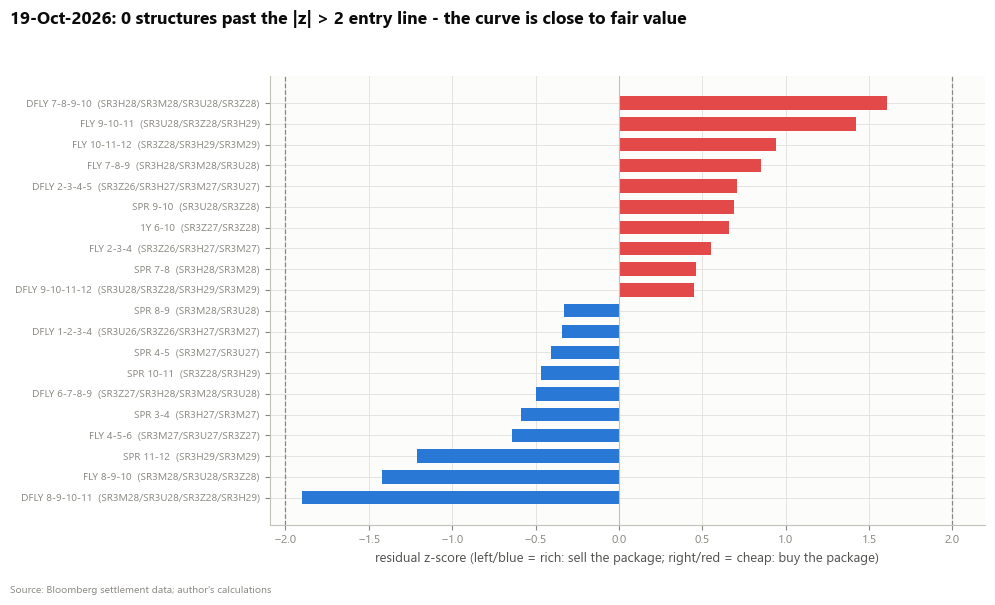

In [11]:
top = top_rich_cheap(r["screen"], 10)
display(top[["structure", "contracts", "z", "residual_bp", "view", "half_life_days", "pca_neutral_weights", "oos_hit_gross", "target_bp", "stop_bp"]])
plots.fig_today(top, b["params"].entry_z);

## What a trader takes away

1. The SOFR curve is ~99% three shapes; anything a fly does beyond them is small (1-3 bp sigma in the belly and back)
   and short-lived (half-life 3-7 days).
2. Those dislocations do revert, but the edge is about a quarter of a basis point per trade - smaller than crossing one
   tick on one leg. Do not run this as a stand-alone strategy that pays the offer.
3. Where it helps: as a timing overlay for trades you want anyway (enter a fly you like on the cheap side of its
   residual), for sizing PCA-neutral hedges, and for spotting the rare |z| > 3.5 dislocation, where the reversion is
   larger (~1 bp in 10 days).
4. To turn it into a strategy you would need passive execution (earning, not paying, the bid-offer) or a sharper signal
   - e.g. add flow / open-interest or event information.